In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
from collections import defaultdict
import itertools
from temporal_encoder import split_dates, build_snapshot_tensor, apply_mask_to_embedding
from adjacency import build_adjacency, mask_adjacency
from gnn import GAT
from train import train_ppo, save_checkpoint, load_checkpoint
from evaluate import evaluate, inspect_weights
import matplotlib.pyplot as plt

In [2]:
def compute_rsi(prices, n=14):

    """ tính chỉ số RSI của cổ phiếu, mặc định 14"""

    delta = prices.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/n, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/n, adjust=False).mean()
    rs = avg_gain / avg_loss
    return 100 - 100 / (1 + rs)

def compute_amihud(close, value, window=20, eps=1e-12):

    """ tính chỉ số Amihud"""

    close = pd.Series(close)
    value = pd.Series(value)
    simple_return = close.pct_change(1)
    illiq_raw = simple_return.abs() / value
    amihud_rolling = illiq_raw.rolling(window=window).mean()
    log_amihud = np.log(amihud_rolling + eps)
    return log_amihud

def FS_crawl(ticker, type):

    """crawl BCTC các cổ phiếu từ web"""
    
    params = {"type": type,
            "year": 2025,
            "quarter": 3,
            "limit": 48}

    frames = []

    for stock in ticker:
        BASE_URL = f"https://api.fireant.vn/symbols/{stock}/full-financial-reports"

        try:
            response = requests.get(BASE_URL, params=params, headers=headers)
            data = response.json()
        except:
            continue

        try:
            metric_dict = {}
            for item in data:
                name = item.get("name")
                if not name:
                    continue
                    
                values = item.get("values", [])
                year_values = {}
                for entry in values:
                    year = entry.get('period')
                    value = entry.get('value')
                    if year is not None and value is not None:
                        year_values[str(year)] = value
                
                if year_values:
                    if name in metric_dict:
                        i = 2
                        while f"{name}_{i}" in metric_dict:
                            i += 1
                        name = f"{name}_{i}"
                    metric_dict[name] = year_values

            if not metric_dict:
                continue

            df_clean = pd.DataFrame(metric_dict).T  # rows=metrics, cols=periods
            df_clean = df_clean.T                    # rows=periods, cols=metrics
            df_clean = df_clean.reset_index()
            df_clean = df_clean.rename(columns={'index': 'index_col'})

            split_data = df_clean['index_col'].str.split(' ', expand=True)
            df_clean.insert(0, 'year', split_data[1])
            df_clean.insert(0, 'quarter', split_data[0])
            df_clean.insert(0, 'ticker', stock)
            df_clean = df_clean.drop(['index_col'], axis=1)

            if type == 1:
                df_clean.to_parquet(os.path.join("stock_bs", f'{stock}.parquet'), engine="pyarrow", index=False)
            elif type == 2:
                df_clean.to_parquet(os.path.join("stock_is", f'{stock}.parquet'), engine="pyarrow", index=False)
            print(f"Successfully for {stock}")


        except Exception as e:
            print(f"Error processing {stock}: {e}")
            continue

    if not frames:
        return pd.DataFrame()

In [ ]:
"""lấy period dataset theo ngày giao dịch của cổ phiếu (ko phải theo ngày theo lịch), data 10 năm 2016 - 2025"""
# lưu ý có thể bị lỗi Connection Error hoặc JSONDecodeError: Expecting value: line 1 column 1 (char 0)
# lỗi này là do phía nguồn request bị lỗi, chờ chút và chạy lại code lần nữa là đc

headers = {
    'Authorization': 
    "YOUR_API_KEY_HERE"
          }

start_date = datetime.datetime(2015,1,1)
end_date = datetime.datetime(2025,12,31)

params = {"startDate":start_date,
          "endDate": end_date,
          "limit": 10000}

BASE_URL = f"https://api.fireant.vn/symbols/VIC/historical-quotes"

response = requests.get(BASE_URL, params=params, headers=headers)
data = response.json()
df = pd.DataFrame(data)

df_clean = df.copy()

df_clean['date'] = pd.to_datetime(df_clean['date'])
df_clean = df_clean.sort_values(by='date', ascending=True).reset_index(drop=True)

base_date = df_clean['date']
data_set_date = base_date[base_date >= datetime.datetime(2016,1,1)]

In [4]:
""" lấy từ file Total_MKC.xlsx danh sách các cổ phiếu đạt tiêu chí vốn hóa vừa và lớn giai đoạn 2015 - 2025, tần suất update tiêu chí 6 tháng 1 lần"""

market_cap = pd.read_excel(os.path.join("raw_data", 'Total_MKC.xlsx'), sheet_name= 'mkc')
market_cap['Dates'] = pd.to_datetime(market_cap['Dates'])
market_cap = market_cap.set_index("Dates")

list_stock = market_cap.reset_index().melt(
    id_vars='Dates',
    var_name='symbol',
    value_name='market_cap'
)

list_stock = list_stock.rename(columns={'Dates': 'date'})
list_stock = list_stock.dropna(subset=['market_cap'])
list_stock = list_stock[['symbol', 'date', 'market_cap']]

# tạm loại bỏ các cổ phiếu k còn giao dịch (dù survivorship bias do data ko còn available) và 2 mã chứng chỉ quỹ
list_stock = list_stock[~list_stock['symbol'].isin(['E1VFVN30', 'FUEVFVND', 'GE2', 'FLC', 'SQC','TBH', 'ROS', 'CAB', 'GTN', 'PME', 'BHS'])]
list_stock['size_category'] = np.where(
    list_stock['market_cap'] > 5e+06,
    'check',
    None
)

In [5]:
""" crawl data giá giao dịch cổ phiếu và tính ra các chỉ số kỹ thuật, data sau đó sẽ được lưu vào folder stock_value, nếu đã có rồi thì skip cell này"""

# symbol = ['VIC']

# start_date = datetime.datetime(2015,1,1)
# end_date = datetime.datetime(2025,12,31)

# params = {"startDate":start_date,
#           "endDate": end_date,
#           "limit": 10000}

# headers = {
#     'Authorization': 
#     'Bearer eyJ0eXAiOiJKV1QiLCJhbGciOiJSUzI1NiIsIng1dCI6IkdYdExONzViZlZQakdvNERWdjV4QkRITHpnSSIsImtpZCI6IkdYdExONzViZlZQakdvNERWdjV4QkRITHpnSSJ9.eyJpc3MiOiJodHRwczovL2FjY291bnRzLmZpcmVhbnQudm4iLCJhdWQiOiJodHRwczovL2FjY291bnRzLmZpcmVhbnQudm4vcmVzb3VyY2VzIiwiZXhwIjoyMDYzOTU3MzExLCJuYmYiOjE3NjM5NTczMTEsImNsaWVudF9pZCI6ImZpcmVhbnQud2ViIiwic2NvcGUiOlsib3BlbmlkIiwicHJvZmlsZSIsInJvbGVzIiwiZW1haWwiLCJhY2NvdW50cy1yZWFkIiwiYWNjb3VudHMtd3JpdGUiLCJvcmRlcnMtcmVhZCIsIm9yZGVycy13cml0ZSIsImNvbXBhbmllcy1yZWFkIiwiaW5kaXZpZHVhbHMtcmVhZCIsImZpbmFuY2UtcmVhZCIsInBvc3RzLXdyaXRlIiwicG9zdHMtcmVhZCIsInN5bWJvbHMtcmVhZCIsInVzZXItZGF0YS1yZWFkIiwidXNlci1kYXRhLXdyaXRlIiwidXNlcnMtcmVhZCIsInNlYXJjaCIsImFjYWRlbXktcmVhZCIsImFjYWRlbXktd3JpdGUiLCJibG9nLXJlYWQiLCJpbnZlc3RvcGVkaWEtcmVhZCJdLCJzdWIiOiIzYmE3M2VjMS0xOGUzLTQyNTAtYTBmMy1iZDMyNWE3ZjdjOGMiLCJhdXRoX3RpbWUiOjE3NjM5NTcyODUsImlkcCI6Ikdvb2dsZSIsIm5hbWUiOiJnaWFiYWNoLm5ndXllbm5AZ21haWwuY29tIiwic2VjdXJpdHlfc3RhbXAiOiJkNjQ2MTU2My1kYWM5LTQ3MmEtOGIxNC1kOGFmMjhjNjljZjYiLCJqdGkiOiJlYWU3NzUyYTdkYjMzNTc5OTIyNDAxODEwMTU5ZTRiZCIsImFtciI6WyJleHRlcm5hbCJdfQ.Vl95Z0vCc594Bu5hyQ_30wf9W7JZqPjAirEkvqhgLhUfZFKlbZsZpCs0dhl3qpZhGu5Bl6wpnSgGaKHXvBHc3CH-nJEj7yS6HlxB5vl7wJ961ftbNzMwGGzxKBr1P-O4b5Dmre6vCwOjhYy19AFJmNwYbu0DOTLl57DlmprehglGY1_sYgKPbjrQOTA_QsZZUy9EtcM9_cnnbWW1dUFB2KPEAFkK3ZXpJQJwaG4V7MhdMEsMPwyjp9imOZH5BtTbFqWRK2mX7IQjYMnvsnM2kanij2ly8qiZcGuWFLkTefPv0u_elIVhI3j-7kO4YyE4FQQ3-vrCGNgftj2mLkhREA'
#           }


# for ticker in symbol:
#     BASE_URL = f"https://api.fireant.vn/symbols/{ticker}/historical-quotes"

#     response = requests.get(BASE_URL, params=params, headers=headers)
#     data = response.json()
#     df = pd.DataFrame(data)

#     df_clean = df.copy()

#     df_clean['date'] = pd.to_datetime(df_clean['date'])
#     df_clean = df_clean.sort_values(by='date', ascending=True).reset_index(drop=True)

#     df_clean['symbol'] = ticker

#     df_clean['log_return'] = np.log((df_clean['priceClose'] + 1e-12) / df_clean['priceClose'].shift(1))
#     df_clean['log_volume'] = np.log((df_clean['totalVolume'] + 1e-12) / df_clean['totalVolume'].shift(1))
#     df_clean['volatility_20d'] = df_clean['log_return'].rolling(window=20).std()*np.sqrt(252) # annualize volatility 1 thang (20 ngay giao dich/thang)
#     df_clean['volatility_60d'] = df_clean['log_return'].rolling(window=60).std()*np.sqrt(252) # annualize volatility 1 quy (60 ngay giao dich/quy)
#     df_clean['rsi_14'] = df_clean['priceClose'].transform(lambda x: compute_rsi(x, n=14))
#     df_clean['momentum_20d'] = df_clean['priceClose'].transform(lambda x: np.log((x + 1e-12) / (x.shift(20) + 1e-12)))
#     df_clean['momentum_60d'] = df_clean['priceClose'].transform(lambda x: np.log((x + 1e-12) / (x.shift(60) + 1e-12)))
#     df_clean['MA20'] = df_clean['priceClose'].transform(lambda x: x.rolling(20).mean())
#     df_clean['MA50'] = df_clean['priceClose'].transform(lambda x: x.rolling(50).mean())
#     df_clean["ma_ratio"] = df_clean['MA20']/df_clean['MA50']
#     df_clean['log_amihud_20d'] = compute_amihud(df_clean['priceClose'], df_clean['totalValue'], window=20)

#     df_clean = df_clean.drop(columns=["priceClose", "totalVolume", "priceHigh", "priceLow", "priceOpen", "priceAverage", "priceBasic", "dealVolume", "putthroughVolume", "totalValue", "putthroughValue",
#                                         "buyForeignQuantity", "buyForeignValue","sellForeignQuantity", "sellForeignValue", "buyCount", "buyQuantity", "sellCount", "sellQuantity",
#                                         "adjRatio", "currentForeignRoom", "propTradingNetDealValue", "propTradingNetPTValue", "propTradingNetValue", "unit", "MA20", "MA50"])

#     # 1. Define your full date range

#     # 2. Set 'date' as index temporarily to perform the reindex
#     df_clean = df_clean.set_index('date')

#     # 3. Reindex to the full range
#     # This adds missing dates and fills them with NaN automatically
#     df_clean = df_clean.reindex(base_date)

#     # 4. Restore the 'date' column and 'symbol' information
#     df_clean.index.name = 'date'
#     df_clean = df_clean.reset_index()

#     # Because we reindexed, 'symbol' column will be NaN for missing dates
#     # Fill the 'symbol' column with the current ticker
#     df_clean['symbol'] = ticker


#     output_dir = "stock_value"
#     file_path = os.path.join(output_dir, f"{ticker}.parquet")

#     df_clean.to_parquet(file_path, engine="pyarrow", index=False)

#     print(f"Successfully saved DataFrame to {file_path}")

# df_clean

' crawl data giá giao dịch cổ phiếu và tính ra các chỉ số kỹ thuật, data sau đó sẽ được lưu vào folder stock_value, nếu đã có rồi thì skip cell này'

In [6]:
""" lấy data giá và chỉ số kỹ thuật từ folder stock_value đã lưu"""

current_dir = os.getcwd() 
output_dir = os.path.join(current_dir, "stock_value")

df_list = []

if os.path.exists(output_dir):
    for ticker_file in os.listdir(output_dir):
        if ticker_file.endswith('.parquet'):
            ticker = ticker_file.replace('.parquet', '')
            file_path = os.path.join(output_dir, f"{ticker}.parquet")
            
            df_single = pd.read_parquet(file_path)
            df_list.append(df_single)

    if df_list:
        merged_df = pd.concat(df_list, ignore_index=True)
        print(f"đã lấy được {len(df_list)} cổ phiếu từ: {output_dir}")
    else:
        print(f"không tìm thấy: {output_dir}")
else:
    print(f"không có file '{output_dir}' ")

merged_df

đã lấy được 222 cổ phiếu từ: d:\KhoaLuanDinhHaiLuong\stock_value


,date,symbol,log_return,log_volume,volatility_20d,volatility_60d,rsi_14,momentum_20d,momentum_60d,ma_ratio,log_amihud_20d
0,2015-01-05,AAA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-06,AAA,1.438874e-02,0.467007,NaN,NaN,100.000000,NaN,NaN,NaN,NaN
2,2015-01-07,AAA,3.509132e-02,0.981959,NaN,NaN,100.000000,NaN,NaN,NaN,NaN
3,2015-01-08,AAA,-2.090668e-02,-1.274064,NaN,NaN,90.561798,NaN,NaN,NaN,NaN
4,2015-01-09,AAA,-2.135312e-02,0.799969,NaN,NaN,82.206182,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
609607,2025-12-25,VTP,-5.125588e-03,0.250081,0.211316,0.378033,41.260329,-0.025369,0.007220,0.950479,-27.392298
609608,2025-12-26,VTP,-3.088011e-03,0.787564,0.209934,0.375552,40.493188,-0.020409,0.025054,0.950065,-27.396499
609609,2025-12-29,VTP,1.021405e-14,0.616806,0.184422,0.375552,40.493188,-0.046333,0.025054,0.949223,-27.422687
609610,2025-12-30,VTP,1.127639e-02,-1.467044,0.180798,0.375756,44.853344,-0.017181,0.026861,0.950767,-27.422180


In [7]:
""" lấy data từ file pe_pb.xlsx để format lại cho phù hợp dataframe tổng và lưu vào file pe_pb_result.xlsx, nếu đã có rồi thì skip"""

# pe_set_1 = pd.read_excel(os.path.join("raw_data", 'pe_pb.xlsx'), sheet_name='Sheet2', header=None)

# tickers_row_1 = pe_set_1.iloc[0].tolist()
# metrics_row_1 = pe_set_1.iloc[1].tolist()

# ticker_series_1 = pd.Series(tickers_row_1).ffill()

# date_col_1 = 0

# ticker_cols_1 = {}
# for i, (ticker, metric) in enumerate(zip(ticker_series_1, metrics_row_1)):
#     if i == 0:
#         continue
#     ticker = str(ticker).strip()
#     metric = str(metric).strip()
#     if ticker not in ticker_cols_1:
#         ticker_cols_1[ticker] = {}
#     if metric == 'PE_RATIO':
#         ticker_cols_1[ticker]['PE'] = i
#     elif metric == 'PX_TO_BOOK_RATIO':
#         ticker_cols_1[ticker]['PB'] = i

# data_rows_1 = pe_set_1.iloc[2:].reset_index(drop=True)

# rows_1 = []
# for ticker, cols in ticker_cols_1.items():
#     pe_idx = cols.get('PE')
#     pb_idx = cols.get('PB')
#     for _, row in data_rows_1.iterrows():
#         pe_val = row[pe_idx] if pe_idx is not None else None
#         pb_val = row[pb_idx] if pb_idx is not None else None
#         rows_1.append({
#             'date': row[date_col_1],
#             'symbol': ticker,
#             'PE_RATIO': None if str(pe_val) in ('nan', '#N/A') else pe_val,
#             'PX_TO_BOOK_RATIO': None if str(pb_val) in ('nan', '#N/A') else pb_val,
#         })

# result_1 = pd.DataFrame(rows_1)
# result_1['date'] = pd.to_datetime(result_1['date'])
# result_1 = result_1.sort_values(['symbol', 'date']).reset_index(drop=True)

# pe_set_2 = pd.read_excel(os.path.join("raw_data", 'pe_pb.xlsx'), sheet_name='Sheet3', header=None)

# tickers_row_2 = pe_set_2.iloc[0].tolist()
# metrics_row_2 = pe_set_2.iloc[1].tolist()

# ticker_series_2 = pd.Series(tickers_row_2).ffill()

# date_col_2 = 0

# ticker_cols_2 = {}
# for i, (ticker, metric) in enumerate(zip(ticker_series_2, metrics_row_2)):
#     if i == 0:
#         continue
#     ticker = str(ticker).strip()
#     metric = str(metric).strip()
#     if ticker not in ticker_cols_2:
#         ticker_cols_2[ticker] = {}
#     if metric == 'PE_RATIO':
#         ticker_cols_2[ticker]['PE'] = i
#     elif metric == 'PX_TO_BOOK_RATIO':
#         ticker_cols_2[ticker]['PB'] = i

# data_rows_2 = pe_set_2.iloc[2:].reset_index(drop=True)

# rows_2 = []
# for ticker, cols in ticker_cols_2.items():
#     pe_idx = cols.get('PE')
#     pb_idx = cols.get('PB')
#     for _, row in data_rows_2.iterrows():
#         pe_val = row[pe_idx] if pe_idx is not None else None
#         pb_val = row[pb_idx] if pb_idx is not None else None
#         rows_2.append({
#             'date': row[date_col_2],
#             'symbol': ticker,
#             'PE_RATIO': None if str(pe_val) in ('nan', '#N/A') else pe_val,
#             'PX_TO_BOOK_RATIO': None if str(pb_val) in ('nan', '#N/A') else pb_val,
#         })

# result_2 = pd.DataFrame(rows_2)
# result_2['date'] = pd.to_datetime(result_2['date'])
# result_2 = result_2.sort_values(['symbol', 'date']).reset_index(drop=True)

# pe_merged = pd.concat([result_1, result_2], ignore_index=True)
# pe_merged = pe_merged.sort_values(['symbol', 'date']).reset_index(drop=True)

# pe_merged = pe_merged[~pe_merged['symbol'].isin(['E1VFVN30', 'FUEVFVND'])]

# pe_merged.to_csv(os.path.join("raw_data", 'pe_pb_result.csv'), index = False)

' lấy data từ file pe_pb.xlsx để format lại cho phù hợp dataframe tổng và lưu vào file pe_pb_result.xlsx, nếu đã có rồi thì skip'

In [8]:
""" crawl data P/E và P/B từ file pe_pb_result.xlsx"""

pe_merged = pd.read_csv(os.path.join("raw_data", 'pe_pb_result.csv'), parse_dates=['date'])

merged_df = merged_df.merge(pe_merged, on=['date', 'symbol'], how='left')

In [9]:
""" thêm mask để phân loại cổ phiếu đạt đủ tiêu chí để cho vào danh mục train, mask = 1 phù hợp, mask = 0 bị loại"""

new_df = pd.DataFrame()
unique_dates = sorted(list_stock['date'].unique())

timeline_df = pd.DataFrame({'start_date': unique_dates})
timeline_df['end_date'] = timeline_df['start_date'].shift(-1)
timeline_df['end_date'] = timeline_df['end_date'].fillna(timeline_df['start_date'] + pd.Timedelta(days=182))

list_stock_timemap = pd.merge(list_stock, timeline_df, left_on='date', right_on='start_date', how='left')

merged_df = merged_df.sort_values('date')
list_stock_timemap = list_stock_timemap.sort_values('date')

new_df = pd.merge_asof(
    merged_df,
    list_stock_timemap[['symbol', 'date', 'size_category', 'end_date']], 
    on='date',
    by='symbol',
    direction='backward'
)

out_of_bound = new_df['date'] >= new_df['end_date']
new_df.loc[out_of_bound, 'size_category'] = pd.NA

new_df = new_df.drop(columns=['end_date']).sort_values(['symbol', 'date'])

# vốn hóa thuộc nhóm cổ phiếu vừa và lớn (trên 5000 tỷ VND)
is_not_nan = new_df['size_category'].notna()
# thời gian giao dịch ít nhất 6 tháng kể từ thời điểm niêm yết (tính theo 126 phiên giao dịch)
is_not_nan_6m_ago = new_df.groupby('symbol')['log_return'].shift(126).notna()

# Áp dụng logic cả 2 điều kiện phải cùng thỏa mãn thì mask = 1, còn lại ko đạt thì mask = 0
new_df['mask'] = ((is_not_nan) & (is_not_nan_6m_ago)).astype(int)

new_df = new_df.drop(columns=['size_category'])
new_df = new_df[new_df['date'].isin(data_set_date)].copy()

In [10]:
""" lấy data chỉ số vĩ mô, apply chung cho tất cả các cổ phiếu"""

df_cpi = pd.read_excel(os.path.join("raw_data", "cpi_yoy.xlsx"))
df_cpi['date'] = pd.to_datetime(df_cpi['date'])
filtered_df_cpi = df_cpi[df_cpi['date'].isin(base_date)].copy()

df_bond = pd.read_excel(os.path.join("raw_data", "vietnam_bond_yield.xlsx"))
df_bond['Date'] = pd.to_datetime(df_bond['Date'])
filtered_df_bond = df_bond[df_bond['Date'].isin(base_date)].copy()
filtered_df_bond = filtered_df_bond.drop(columns=["Open", "High", "Low", "Change %"])
filtered_df_bond.rename(columns={'Price': 'bond_yield', "Date": "date"}, inplace=True)

df_interbankrate = pd.read_excel(os.path.join("raw_data", "interbank_rate.xlsx"))
df_interbankrate['date'] = pd.to_datetime(df_interbankrate['date'])
filtered_df_interbankrate = df_interbankrate[df_interbankrate['date'].isin(base_date)].copy()
filtered_df_interbankrate = filtered_df_interbankrate.drop(columns=["maturity"])

df_vnindex = pd.read_excel(os.path.join("raw_data", "vnindex_daily_returns.xlsx"))
df_vnindex['date'] = pd.to_datetime(df_vnindex['date'])
filtered_df_vnindex = df_vnindex[df_vnindex['date'].isin(base_date)].copy()
filtered_df_vnindex = filtered_df_vnindex.drop(columns=["vnindex"])
filtered_df_vnindex.rename(columns={"return_pct": "vnindex_return"}, inplace=True)

df_fx = pd.read_excel(os.path.join("raw_data", "usd_vnd_fx_rate.xlsx"))
df_fx['date'] = pd.to_datetime(df_fx['date'])
filtered_df_fx = df_fx[df_fx['date'].isin(base_date)].copy()
filtered_df_fx = filtered_df_fx.drop(columns=["Open", "High", "Low", "Change %"])
filtered_df_fx.rename(columns={"Close": "usdvnd_fx_rate"}, inplace=True)

merged_df = (
    pd.concat([filtered_df_cpi, filtered_df_bond, filtered_df_interbankrate, filtered_df_vnindex, filtered_df_fx], axis=0)
    .groupby("date", as_index=False)
    .first()
)

merged_df = merged_df.sort_values(by='date').reset_index(drop=True)
merged_df = merged_df.set_index('date').ffill().reset_index()
merged_df = merged_df.set_index('date').bfill().reset_index()
filtered_merged_df = merged_df[merged_df['date'].isin(data_set_date)].reset_index(drop=True)

new_df = new_df.merge(filtered_merged_df, on='date', how='left')

In [11]:
""" crawl BCTC, lấy thời gian công bố thông tin"""

# match new financial statment publish time
# frame = []

# for i in list(list_stock['symbol'].unique()):
#     TIMESCALE_URL = f"https://api.fireant.vn/symbols/{i}/timescale-marks"

#     timescale_response = requests.get(TIMESCALE_URL, params=params, headers=headers)
#     timescale_data = timescale_response.json()
#     timescale_df = pd.DataFrame(timescale_data)

#     timescale_df['date'] = pd.to_datetime(timescale_df['date'])
#     df_quarter = timescale_df[timescale_df['title'].str.contains('BCTC quý')].copy()  # add .copy()
#     df_quarter['ticker'] = i
#     df_quarter['quarter'] = 'Q' + df_quarter['title'].str.extract(r'quý\s*(\d)').astype(str)
#     df_quarter['year'] = df_quarter['title'].str.extract(r'(\d{4})')
#     frame.append(df_quarter)

# total_df_quarter = pd.concat(frame,axis=0, ignore_index=True, sort=False)

# total_df_quarter

' crawl BCTC, lấy thời gian công bố thông tin'

In [12]:
""" crawl BCTC, lấy bảng cân đối kế toán"""

# base_bs = FS_crawl(ticker=list(list_stock['symbol'].unique()), type=1).copy() # type 1: Ban can doi ke toan (Balance Sheet)

# crawl new data
# ticker_test = ['ABB']
# base_bs = FS_crawl(ticker=ticker_test, type=1)

# run data from parquet file
# df_bs = []
# if os.path.exists(os.path.join(current_dir, "stock_bs")):
#     for ticker_file in os.listdir(os.path.join(current_dir, "stock_bs")):
#         if ticker_file.endswith('.parquet'):
#             # This matches your exact syntax pattern dynamically
#             ticker = ticker_file.replace('.parquet', '')
#             file_path = os.path.join(os.path.join(current_dir, "stock_bs"), f"{ticker}.parquet")
            
#             # Read and collect
#             df_single = pd.read_parquet(file_path)
#             df_bs.append(df_single)

#     # 5. Merge everything together
#     if df_bs:
#         base_bs = pd.concat(df_bs, ignore_index=True)
#         print(f"Successfully merged {len(df_bs)} files")
#     else:
#         print(f"No Parquet files found")
# else:
#     print(f"Error: The folder does not exist relative to your current code location.")

# base_bs['equity'] = base_bs['B. Nguồn vốn chủ sở hữu'].combine_first(
#     base_bs['VIII. Vốn và các quỹ']
# ).combine_first(
#     base_bs['D. VỐN CHỦ SỞ HỮU']
# )

# base_bs

' crawl BCTC, lấy bảng cân đối kế toán'

In [13]:
""" crawl BCTC, lấy báo cáo kết quả kinh doanh"""

# base_is = FS_crawl(ticker=list(list_stock['symbol'].unique()), type=2).copy() # type 2: Bao cao ket qua kinh doanh (Income Statement)

# crawl new data
# ticker_test = [ 'VIC']
# base_is = FS_crawl(ticker=ticker_test, type=2)

#run data from parquet file
# df_is = []
# if os.path.exists(os.path.join(current_dir, "stock_is")):
#     for ticker_file in os.listdir(os.path.join(current_dir, "stock_is")):
#         if ticker_file.endswith('.parquet'):
#             # This matches your exact syntax pattern dynamically
#             ticker = ticker_file.replace('.parquet', '')
#             file_path = os.path.join(os.path.join(current_dir, "stock_is"), f"{ticker}.parquet")
            
#             # Read and collect
#             df_single = pd.read_parquet(file_path)
#             df_is.append(df_single)

#     # 5. Merge everything together
#     if df_is:
#         base_is = pd.concat(df_is, ignore_index=True)
#         print(f"Successfully merged {len(df_is)} files")
#     else:
#         print(f"No Parquet files found ")
# else:
#     print(f"Error: The folder does not exist relative to your current code location.")

# base_is['net income'] = base_is['XI. LỢI NHUẬN KẾ TOÁN SAU THUẾ TNDN'].combine_first(
#     base_is['Lợi nhuận sau thuế thu nhập doanh nghiệp']
# ).combine_first(
#     base_is['19. Lợi nhuận sau thuế thu nhập doanh nghiệp (15)-(18)']
# )

# base_is

' crawl BCTC, lấy báo cáo kết quả kinh doanh'

In [14]:
""" tính chỉ số tài chính và lưu kết quả vào file financial_data.xlsx, nếu đã có rồi thì skip"""

# financial_df = pd.DataFrame(list(itertools.product(list_stock['symbol'].unique(), ['Q1', 'Q2', 'Q3', 'Q4'], range(2013, 2026))), columns=['symbol', 'quarter', 'year'])
# financial_df['year'] = financial_df['year'].astype(int)
# base_is['year'] = base_is['year'].astype(int)
# base_bs['year'] = base_bs['year'].astype(int)
# total_df_quarter['year'] = total_df_quarter['year'].astype(int)

# financial_df = financial_df.sort_values(['symbol', 'year', 'quarter']).reset_index(drop=True)

# base_is['NI_4Q'] = (base_is.groupby('ticker')['net income'].rolling(window=4, min_periods=4).sum().reset_index(level=0, drop=True))
# financial_df = financial_df.merge(base_is[['ticker', 'quarter', 'year', 'NI_4Q']],left_on=['symbol', 'quarter', 'year'],right_on=['ticker', 'quarter', 'year'],how='left').drop(columns='ticker')
# financial_df['Net income growth'] = financial_df.groupby('symbol')['NI_4Q'].pct_change(4, fill_method=None)


# financial_df = financial_df.merge(base_bs[['ticker', 'quarter', 'year', 'equity', 'TỔNG CỘNG TÀI SẢN']],left_on=['symbol', 'quarter', 'year'],right_on=['ticker', 'quarter', 'year'],how='left').drop(columns='ticker')
# financial_df['ROE'] = financial_df['NI_4Q'] / financial_df['equity']
# financial_df['A/E'] = financial_df['TỔNG CỘNG TÀI SẢN'] / financial_df['equity']

# financial_df = financial_df.drop(columns=['NI_4Q', 'equity', 'TỔNG CỘNG TÀI SẢN'])

# financial_df = financial_df.merge(total_df_quarter[['ticker', 'quarter', 'year', 'date']],left_on=['symbol', 'quarter', 'year'],right_on=['ticker', 'quarter', 'year'], how = 'left').drop(columns='ticker')

# financial_df.to_excel('financial_data.xlsx', index=False)

' tính chỉ số tài chính và lưu kết quả vào file financial_data.xlsx, nếu đã có rồi thì skip'

In [15]:
""" lấy data BCTC từ file financial_data.xlsx"""

financial_df = pd.read_excel(os.path.join("raw_data", 'financial_data.xlsx'))

financial_df_clean = financial_df.dropna(subset=['date'])
financial_df_clean = financial_df_clean.groupby(['symbol', 'date']).first().reset_index()

ticker = financial_df_clean['symbol'].unique()
all_date = pd.date_range(start=start_date, end=end_date, freq='D')

idx = pd.MultiIndex.from_product([ticker, all_date], names=['symbol', 'date'])

financial_df_expanded = (financial_df_clean.set_index(['symbol', 'date']).reindex(idx).groupby(level='symbol').ffill().reset_index())

final_df = new_df.merge(financial_df_expanded, on = ['symbol', 'date'], how = 'left')
final_df = final_df.drop(columns=['quarter', 'year'])

final_df

,date,symbol,log_return,log_volume,volatility_20d,volatility_60d,rsi_14,momentum_20d,momentum_60d,ma_ratio,...,PX_TO_BOOK_RATIO,mask,inflation,bond_yield,interbank_rate,vnindex_return,usdvnd_fx_rate,Net income growth,ROE,A/E
0,2016-01-04,AAA,2.409755e-02,0.398190,0.377062,0.384181,71.705717,0.117783,0.163453,1.021908,...,0.7704,0,0.006000,7.076,0.0491,-0.797886,0.44830,-0.656136,0.024861,1.924670
1,2016-01-05,AAA,6.899287e-02,1.771034,0.437463,0.407409,78.493564,0.186776,0.232446,1.026538,...,0.8254,0,0.006000,7.054,0.0481,-0.778190,0.44830,-0.656136,0.024861,1.924670
2,2016-01-06,AAA,-2.247286e-02,-1.993175,0.450332,0.410791,72.269793,0.146603,0.200671,1.028887,...,0.8071,0,0.006000,7.054,0.0796,0.812366,0.44830,-0.656136,0.024861,1.924670
3,2016-01-07,AAA,7.571721e-14,0.252187,0.447219,0.410791,72.269793,0.155414,0.200671,1.031838,...,0.8071,0,0.006000,7.054,0.0484,-1.602938,0.44830,-0.656136,0.024861,1.924670
4,2016-01-08,AAA,-7.604599e-03,-0.575012,0.432369,0.408874,70.120419,0.174717,0.211758,1.036004,...,0.8010,0,0.006000,7.054,0.0471,-0.939225,0.44830,-0.656136,0.024861,1.924670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
554551,2025-12-25,VTP,-5.125588e-03,0.250081,0.211316,0.378033,41.260329,-0.025369,0.007220,0.950479,...,6.7785,1,0.032455,4.179,0.0547,-2.241948,0.38045,0.070992,0.218551,3.834256
554552,2025-12-26,VTP,-3.088011e-03,0.787564,0.209934,0.375552,40.493188,-0.020409,0.025054,0.950065,...,6.7576,1,0.032455,4.179,0.0431,-0.748774,0.38030,0.070992,0.218551,3.834256
554553,2025-12-29,VTP,1.021405e-14,0.616806,0.184422,0.375552,40.493188,-0.046333,0.025054,0.949223,...,6.7576,1,0.032455,4.182,0.0329,1.447566,0.38040,0.070992,0.218551,3.834256
554554,2025-12-30,VTP,1.127639e-02,-1.467044,0.180798,0.375756,44.853344,-0.017181,0.026861,0.950767,...,6.8343,1,0.032455,4.183,0.0177,0.687242,0.38070,0.070992,0.218551,3.834256


In [16]:
""" train model cho GNN + RL từ các file:
    temporal_encoder.py để chuẩn hóa dữ liệu và embedding bằng LTSM hoặc Transformer
    gnn.py cho GNN
    adjacency.py cho ma trận kề A
    rl_agent cho RL
    train.py để train toàn bộ pipeline 
"""
# tần suất update các cổ phiếu trong danh mục theo tuần (freq = "W"), tối đa 20 cổ phiếu (top_k = 20), tối đa 10% trọng số (w_max = 0.10) -> trọng số mỗi cổ 5% - 10%
result = train_ppo(final_df, n_iters=30, freq='W', top_k=20, w_max=0.10, seed= 1)

# lưu kết quả train để lần sau load nhanh hơn, k cần phải train lại
save_checkpoint(result, 'model_weekly.pt')

Timeline   : 2016-01-04 → 2025-12-31
Train      : 2016-04-11 → 2022-12-26  (349 decision dates)
Validation : 2023-01-03 → 2023-12-25  (52 decision dates)
Test       : 2024-01-02 → 2025-12-29  (104 decision dates)
Device: cuda


d:\KhoaLuanDinhHaiLuong\temporal_encoder.py:344: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Episodes train: 348 | val: 51


d:\KhoaLuanDinhHaiLuong\train.py:197: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  loss_val += float(loss_ep)


iter 00 | reward +0.4793 | val Sharpe -0.030 * | loss +74.0241
iter 01 | reward +0.4681 | val Sharpe -1.115 | loss +71.7985
iter 02 | reward +0.6914 | val Sharpe -0.163 | loss +133.2285
iter 03 | reward +0.5281 | val Sharpe -0.474 | loss +86.6437
iter 04 | reward +0.4097 | val Sharpe -0.688 | loss +57.6587
iter 05 | reward +0.3411 | val Sharpe -0.064 | loss +45.6291
iter 06 | reward +0.5396 | val Sharpe -0.677 | loss +87.2393
iter 07 | reward +0.6071 | val Sharpe +0.496 * | loss +108.6113
iter 08 | reward +0.6067 | val Sharpe -0.432 | loss +99.5478
iter 09 | reward +0.4440 | val Sharpe +0.237 | loss +61.2672
iter 10 | reward +0.4720 | val Sharpe +0.353 | loss +77.4553
iter 11 | reward +0.4571 | val Sharpe -0.320 | loss +63.2218
iter 12 | reward +0.5409 | val Sharpe +0.098 | loss +87.2376
iter 13 | reward +0.6209 | val Sharpe +0.838 * | loss +108.6729
iter 14 | reward +0.5647 | val Sharpe +0.181 | loss +91.1004
iter 15 | reward +0.5979 | val Sharpe +0.378 | loss +96.4560
iter 16 | rewar

In [17]:
""" load kết quả train từ lần trước """

result = load_checkpoint('model_weekly.pt')
evaluate(result, final_df, split='test', freq='W', top_k=20, w_max=0.10)

Đã nạp model ← model_weekly.pt
Timeline   : 2016-01-04 → 2025-12-31
Train      : 2016-04-11 → 2022-12-26  (349 decision dates)
Validation : 2023-01-03 → 2023-12-25  (52 decision dates)
Test       : 2024-01-02 → 2025-12-29  (104 decision dates)


d:\KhoaLuanDinhHaiLuong\temporal_encoder.py:344: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


=== Backtest trên tập TEST (103 kỳ) ===

Chiến lược              Cum.Return    Sharpe     MaxDD
------------------------------------------------------
Agent (GNN+RL)               18.4%      0.53    -14.6%
Equal-weight (1/N)           19.9%      0.58    -17.3%
VN-Index                     55.1%      1.19    -15.2%


{'metrics': {'Agent (GNN+RL)': {'cum_return': 0.1843729564440908,
   'sharpe': 0.5308778832063228,
   'max_drawdown': -0.14592955999223403},
  'Equal-weight (1/N)': {'cum_return': 0.19932422735421285,
   'sharpe': 0.5765416050038312,
   'max_drawdown': -0.17277314822683287},
  'VN-Index': {'cum_return': 0.5505955536705196,
   'sharpe': 1.1942603351336514,
   'max_drawdown': -0.15226827114483718}},
 'series': {'agent': [-0.007528520007091829,
   -0.025273566158977197,
   0.008768749139624048,
   0.01763341097193846,
   -0.0002268835621840983,
   0.011145490160145962,
   0.01563231819645714,
   -0.020635989976901824,
   0.027858837869654703,
   0.013049422155302342,
   -0.001306468219469903,
   -0.006812411646492261,
   0.01199559868296763,
   -0.04110088006976667,
   -0.01876674625013,
   -0.015278267604720347,
   0.05736684248665848,
   0.010289549749242913,
   0.0036662170941059616,
   0.015896585560559683,
   0.019610660592888678,
   0.035094070777055245,
   -0.00314518553244674,
   

In [18]:
""" xem trọng số cổ phiếu tại từng thời điểm update danh mục"""

# inspect_weights(result, final_df, decision_date='2024-01-02',freq='W', top_k=20, w_max=0.10)
inspect_weights(result, final_df, freq='W', top_k=20, w_max=0.10)

Timeline   : 2016-01-04 → 2025-12-31
Train      : 2016-04-11 → 2022-12-26  (349 decision dates)
Validation : 2023-01-03 → 2023-12-25  (52 decision dates)
Test       : 2024-01-02 → 2025-12-29  (104 decision dates)
=== Trọng số agent tại 2025-12-29 ===
Số mã eligible         : 174
Số mã được phân bổ >0  : 20
Weight min / max       : 4.99% / 5.05%
Weight trung bình      : 5.00%
Số mã hiệu dụng (1/HHI): 20.0
Số mã chiếm 90% vốn    : 18

Top 10 phân bổ:
  VNZ      5.05%
  DNH      5.04%
  CC1      5.01%
  PDN      5.00%
  TMS      5.00%
  PAP      5.00%
  PVI      5.00%
  CHP      5.00%
  KDC      5.00%
  HNA      5.00%


(array([0.        , 0.        , 0.        , 0.04990384, 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.05007621, 0.        ,
        0.04997542, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.05044286, 0.        , 0.        , 0.        , 0.04989093,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.  

Timeline   : 2016-01-04 → 2025-12-31
Train      : 2016-04-11 → 2022-12-26  (349 decision dates)
Validation : 2023-01-03 → 2023-12-25  (52 decision dates)
Test       : 2024-01-02 → 2025-12-29  (104 decision dates)


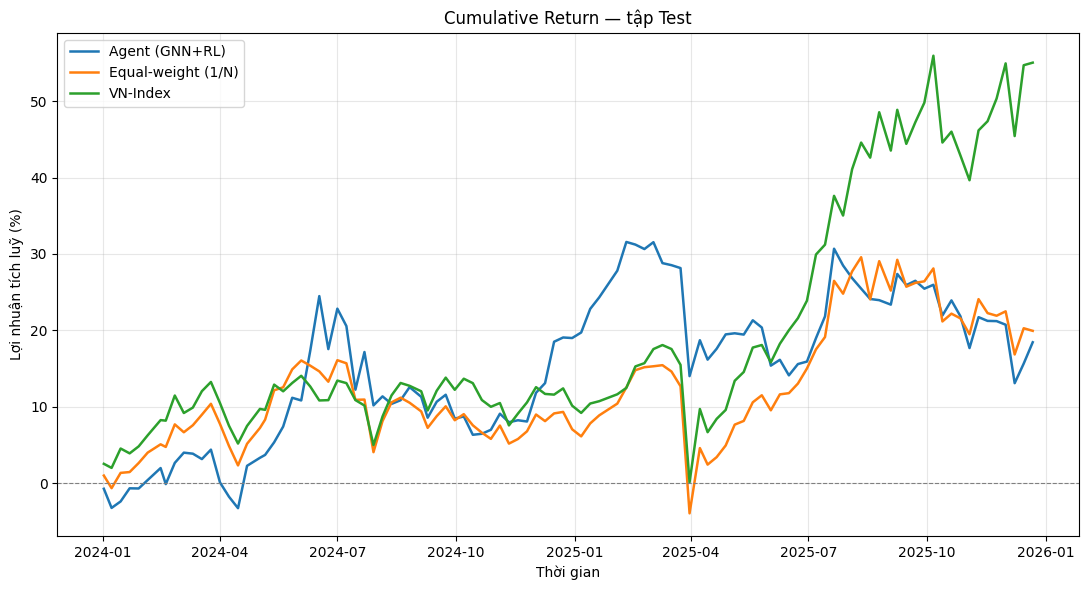

In [19]:
""" plot return theo thời gian """

out = evaluate(result, final_df, split='test', freq='W', top_k=20, w_max=0.10, verbose=False)
s = out['series']

plt.figure(figsize=(11, 6))
for key, label in [('agent', 'Agent (GNN+RL)'),
                   ('equal_weight', 'Equal-weight (1/N)'),
                   ('vnindex', 'VN-Index')]:
    equity = (np.cumprod(1 + np.array(s[key])) - 1) * 100   # lợi nhuận tích luỹ (%)
    plt.plot(s['dates'], equity, label=label, linewidth=1.8)

plt.axhline(0, color='gray', lw=0.8, ls='--')
plt.title('Cumulative Return — tập Test')
plt.xlabel('Thời gian'); plt.ylabel('Lợi nhuận tích luỹ (%)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()